# Image Classification Using a Functional Residual CNN on CIFAR-10

This notebook completes **Part A (50 marks)**. Run it from top to bottom. The training cell automatically saves the best model, final model, CSV log, and history.


## 1. Environment Setup, Hardware Acceleration, and Pipeline Mechanics

In [ ]:
import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.20.0
NumPy: 2.0.2


In [ ]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print(f"GPU acceleration available: {len(gpus)} GPU(s)")
    for i, gpu in enumerate(gpus):
        print(f"GPU {i}:", gpu)
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
else:
    print("No GPU detected. CPU training will be much slower.")

print("\nLogical devices:")
for device in tf.config.list_logical_devices():
    print(device)

No GPU detected. CPU training will be much slower.

Logical devices:
LogicalDevice(name='/device:CPU:0', device_type='CPU')


## 2. High-Complexity Dataset Ingestion and Advanced Pipeline Engineering

In [ ]:
from tensorflow.keras.datasets import cifar10

try:
    (x_train_original, y_train_original), (x_test_original, y_test_original) = cifar10.load_data()
except Exception as error:
    raise RuntimeError(
        "CIFAR-10 could not be loaded. Check the connection and rerun only this cell. "
        "Do not restart while the download is active."
    ) from error

print("CIFAR-10 loaded successfully.")
print("Official train:", x_train_original.shape)
print("Official test:", x_test_original.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3099s 18us/step
CIFAR-10 loaded successfully.
Official train: (50000, 32, 32, 3)
Official test: (10000, 32, 32, 3)


In [ ]:
x_data = np.concatenate([x_train_original, x_test_original], axis=0)
y_data = np.concatenate([y_train_original, y_test_original], axis=0).reshape(-1)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("All images:", x_data.shape)
print("All labels:", y_data.shape)

All images: (60000, 32, 32, 3)
All labels: (60000,)


In [ ]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x_data, y_data,
    test_size=0.30,
    random_state=SEED,
    stratify=y_data
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

assert x_train.shape[0] == 42000
assert x_val.shape[0] == 9000
assert x_test.shape[0] == 9000
assert len(x_train) + len(x_val) + len(x_test) == 60000

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Testing:", x_test.shape, y_test.shape)

Training: (42000, 32, 32, 3) (42000,)
Validation: (9000, 32, 32, 3) (9000,)
Testing: (9000, 32, 32, 3) (9000,)


In [ ]:
def distribution_table(labels, split_name):
    ids, counts = np.unique(labels, return_counts=True)
    return pd.DataFrame({
        "Split": split_name,
        "Class ID": ids,
        "Class Name": [class_names[i] for i in ids],
        "Image Count": counts,
        "Proportion": counts / len(labels)
    })

distribution_df = pd.concat([
    distribution_table(y_train, "Training"),
    distribution_table(y_val, "Validation"),
    distribution_table(y_test, "Testing")
], ignore_index=True)

display(distribution_df)
display(distribution_df.pivot(index="Class Name", columns="Split", values="Image Count"))

,Split,Class ID,Class Name,Image Count,Proportion
0,Training,0,airplane,4200,0.1
1,Training,1,automobile,4200,0.1
2,Training,2,bird,4200,0.1
3,Training,3,cat,4200,0.1
4,Training,4,deer,4200,0.1
5,Training,5,dog,4200,0.1
6,Training,6,frog,4200,0.1
7,Training,7,horse,4200,0.1
8,Training,8,ship,4200,0.1
9,Training,9,truck,4200,0.1


Split,Testing,Training,Validation
Class Name,,,
airplane,900,4200,900
automobile,900,4200,900
bird,900,4200,900
cat,900,4200,900
deer,900,4200,900
dog,900,4200,900
frog,900,4200,900
horse,900,4200,900
ship,900,4200,900


In [ ]:
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Train pixel range:", x_train.min(), "to", x_train.max())
print("Validation pixel range:", x_val.min(), "to", x_val.max())
print("Test pixel range:", x_test.min(), "to", x_test.max())

Train pixel range: 0.0 to 1.0
Validation pixel range: 0.0 to 1.0
Test pixel range: 0.0 to 1.0


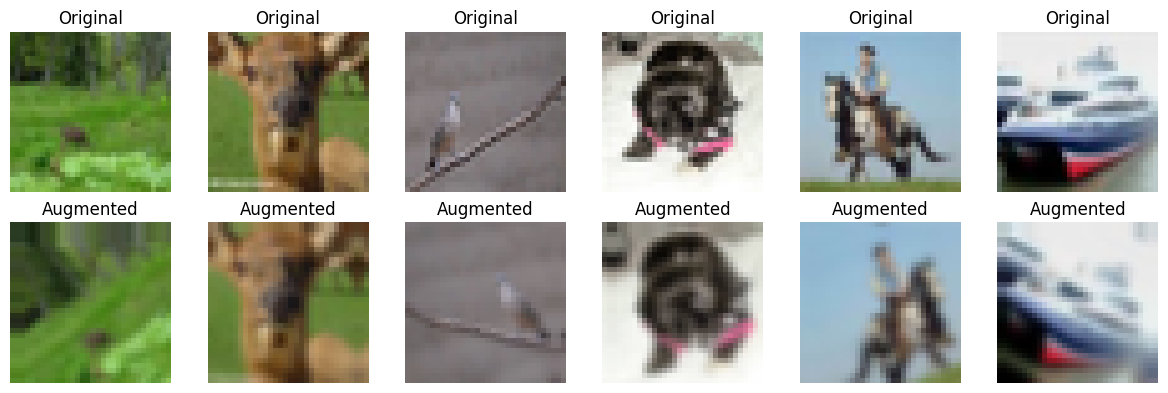

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10)
], name="data_augmentation")

sample_images = x_train[:6]
augmented = data_augmentation(sample_images, training=True)

plt.figure(figsize=(12, 4))
for i in range(6):
    plt.subplot(2, 6, i + 1)
    plt.imshow(sample_images[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 6, i + 7)
    plt.imshow(np.clip(augmented[i].numpy(), 0, 1))
    plt.title("Augmented")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def augment_batch(images, labels):
    return data_augmentation(images, training=True), labels

train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(10000, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(augment_batch, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((x_val, y_val))
    .batch(BATCH_SIZE)
    .cache()
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .batch(BATCH_SIZE)
    .cache()
    .prefetch(AUTOTUNE)
)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 657
Validation batches: 141
Testing batches: 141


### Data Augmentation and Pixel Normalisation

Pixel values were scaled from \([0,255]\) to \([0,1]\). Gradient descent updates parameters using:

$$
\theta_{t+1}=\theta_t-\alpha\nabla J(\theta_t)
$$

Large, inconsistently scaled inputs may create large activations and poorly conditioned gradients. Normalisation reduces activation magnitude and supports smoother updates. Horizontal flipping, rotation, zooming, and translation were applied only to training data to enforce geometric invariance. Validation and testing data were unchanged for unbiased evaluation.

## 3. Custom Architectural Engineering: Functional Residual CNN

In [ ]:
def residual_block(x, filters, block_name):
    # Two-layer residual block with an identity shortcut
    shortcut = x

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        name=f"{block_name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{block_name}_bn1")(x)
    x = layers.ReLU(name=f"{block_name}_relu1")(x)

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        name=f"{block_name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{block_name}_bn2")(x)

    x = layers.Add(name=f"{block_name}_add")([x, shortcut])
    x = layers.ReLU(name=f"{block_name}_output")(x)
    return x


inputs = layers.Input(shape=(32, 32, 3), name="input_image")

# Block 1
x = layers.Conv2D(32, 3, padding="same", use_bias=False, name="block1_conv1")(inputs)
x = layers.BatchNormalization(name="block1_bn1")(x)
x = layers.ReLU(name="block1_relu1")(x)
x = layers.Conv2D(32, 3, padding="same", use_bias=False, name="block1_conv2")(x)
x = layers.BatchNormalization(name="block1_bn2")(x)
x = layers.ReLU(name="block1_relu2")(x)
x = layers.MaxPooling2D(2, name="block1_pool")(x)

# Block 2
x = layers.Conv2D(64, 3, padding="same", use_bias=False, name="block2_conv1")(x)
x = layers.BatchNormalization(name="block2_bn1")(x)
x = layers.ReLU(name="block2_relu1")(x)
x = layers.Conv2D(64, 3, padding="same", use_bias=False, name="block2_conv2")(x)
x = layers.BatchNormalization(name="block2_bn2")(x)
x = layers.ReLU(name="block2_relu2")(x)
x = layers.MaxPooling2D(2, name="block2_pool")(x)

# Block 3: residual block
x = residual_block(x, 64, "residual_block1")

# Block 4
x = layers.Conv2D(128, 3, padding="same", use_bias=False, name="block4_conv1")(x)
x = layers.BatchNormalization(name="block4_bn1")(x)
x = layers.ReLU(name="block4_relu1")(x)
x = layers.Conv2D(128, 3, padding="same", use_bias=False, name="block4_conv2")(x)
x = layers.BatchNormalization(name="block4_bn2")(x)
x = layers.ReLU(name="block4_relu2")(x)
x = layers.MaxPooling2D(2, name="block4_pool")(x)

x = layers.SpatialDropout2D(0.30, name="spatial_dropout")(x)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dense(128, activation="relu", name="dense_128")(x)
x = layers.Dropout(0.40, name="dropout_40")(x)
outputs = layers.Dense(10, activation="softmax", name="classification_output")(x)

model = Model(inputs, outputs, name="CIFAR10_Residual_CNN")
model.summary()

Model: "CIFAR10_Residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 32, 32,    │        864 │ input_image[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_bn1          │ (None, 32, 32,    │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_relu1 (ReLU) │ (None, 32, 32,    │          0 │ block1_bn1[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 32, 32,    │      9,216 │ block1_relu1[0][… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_bn2          │ (None, 32, 32,    │        128 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_relu2 (ReLU) │ (None, 32, 32,    │          0 │ block1_bn2[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 16, 16,    │          0 │ block1_relu2[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 16, 16,    │     18,432 │ block1_pool[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_bn1          │ (None, 16, 16,    │        256 │ block2_conv1[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_relu1 (ReLU) │ (None, 16, 16,    │          0 │ block2_bn1[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 16, 16,    │     36,864 │ block2_relu1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_bn2          │ (None, 16, 16,    │        256 │ block2_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_relu2 (ReLU) │ (None, 16, 16,    │          0 │ block2_bn2[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 8, 8, 64)  │          0 │ block2_relu2[0][… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block1_co… │ (None, 8, 8, 64)  │     36,864 │ block2_pool[0][0] │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_block1_bn1 │ (None, 8, 8, 64)  │        256 │ residual_block1_

 Total params: 380,394 (1.45 MB)

 Trainable params: 379,242 (1.45 MB)

 Non-trainable params: 1,152 (4.50 KB)

### Architectural and Theoretical Justification

Four convolutional blocks learn progressively more abstract features. Batch Normalization computes:

$$
\mu_B=\frac{1}{m}\sum_{i=1}^{m}x_i
$$

$$
\sigma_B^2=\frac{1}{m}\sum_{i=1}^{m}(x_i-\mu_B)^2
$$

$$
\hat{x}_i=\frac{x_i-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}
$$

$$
y_i=\gamma\hat{x}_i+\beta
$$

This stabilises intermediate activation distributions. The residual block computes:

$$
y=F(x)+x
$$

and its identity path provides a direct route for gradients, reducing vanishing-gradient effects. Spatial Dropout at 0.30 removes complete feature maps, Dropout at 0.40 reduces dense-layer co-adaptation, and Global Average Pooling reduces parameters compared with flattening.

### Manual Parameter Verification

For `block4_conv2`:

$$
(3\times3\times128)\times128=147,456
$$

Bias is disabled, so no extra terms are added.

For `block4_bn2`, four values are stored per channel:

$$
4\times128=512
$$

Trainable: \(\gamma+\beta=128+128=256\).  
Non-trainable: moving mean + moving variance \(=128+128=256\).  
Total: \(512\).

## 4. Controlled Training, Optimisation, and Dynamic Learning Rates

In [ ]:
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    CSVLogger,
    BackupAndRestore
)

model.compile(
    optimizer=AdamW(learning_rate=0.001, weight_decay=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks = [
    ModelCheckpoint(
        "best_cifar10_residual_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    CSVLogger("training_log.csv", append=False),
    BackupAndRestore(backup_dir="training_backup")
]

print("Model compiled and callbacks created.")

Model compiled and callbacks created.


AdamW uses adaptive moment estimates with decoupled weight decay:

$$
\theta_{t+1}
=
\theta_t-\alpha\frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\epsilon}
-\alpha\lambda\theta_t
$$

Sparse cross-entropy for the correct class \(y\) is:

$$
L=-\log(p_y)
$$

In [ ]:
# LONG TRAINING CELL — run once
EPOCHS = 50

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

model.save("final_cifar10_residual_cnn.keras")

with open("training_history.json", "w") as history_file:
    json.dump(
        {key: [float(v) for v in values]
         for key, values in history.history.items()},
        history_file
    )

print("Training complete. Model and history saved.")

Epoch 1/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 0s 635ms/step - accuracy: 0.2887 - loss: 1.9234
Epoch 1: val_loss improved from None to 1.78941, saving model to best_cifar10_residual_cnn.keras

Epoch 1: finished saving model to best_cifar10_residual_cnn.keras
657/657 ━━━━━━━━━━━━━━━━━━━━ 452s 669ms/step - accuracy: 0.3581 - loss: 1.7336 - val_accuracy: 0.3759 - val_loss: 1.7894 - learning_rate: 0.0010
Epoch 2/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 0s 631ms/step - accuracy: 0.4773 - loss: 1.4591
Epoch 2: val_loss improved from 1.78941 to 1.72585, saving model to best_cifar10_residual_cnn.keras

Epoch 2: finished saving model to best_cifar10_residual_cnn.keras
657/657 ━━━━━━━━━━━━━━━━━━━━ 436s 664ms/step - accuracy: 0.4965 - loss: 1.4084 - val_accuracy: 0.4304 - val_loss: 1.7258 - learning_rate: 0.0010
Epoch 3/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 0s 628ms/step - accuracy: 0.5444 - loss: 1.2744
Epoch 3: val_loss improved from 1.72585 to 1.52054, saving model to best_cifar10_residual_cnn.keras

Epoch 3: finis

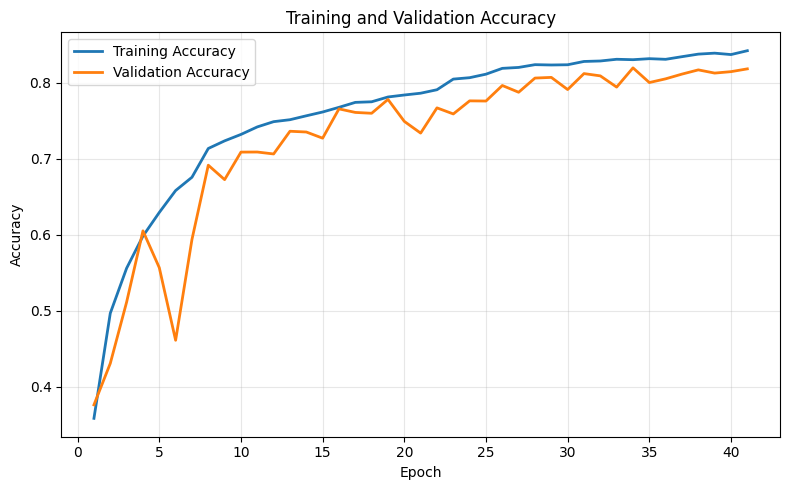

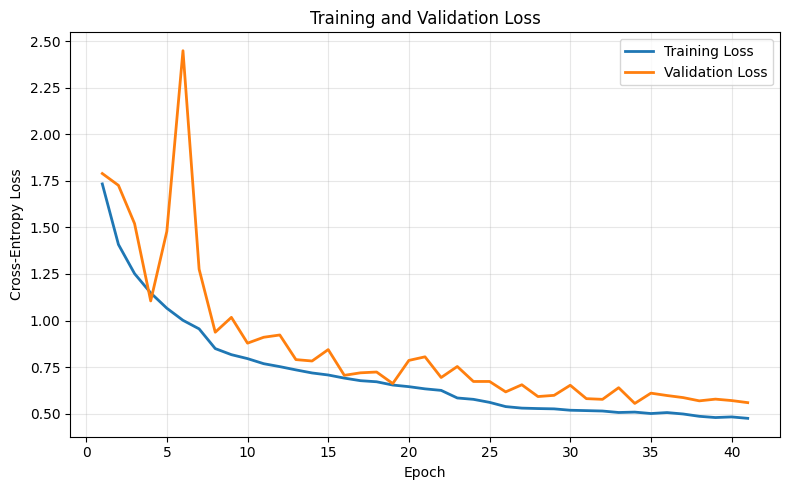

Epochs completed: 41
Final training accuracy: 0.8420000076293945
Final validation accuracy: 0.8181111216545105
Best validation accuracy: 0.8194444179534912
Lowest validation loss: 0.5549608469009399


In [ ]:
epochs_completed = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_completed, history.history["accuracy"], linewidth=2, label="Training Accuracy")
plt.plot(epochs_completed, history.history["val_accuracy"], linewidth=2, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_completed, history.history["loss"], linewidth=2, label="Training Loss")
plt.plot(epochs_completed, history.history["val_loss"], linewidth=2, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Epochs completed:", len(history.history["loss"]))
print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])
print("Best validation accuracy:", max(history.history["val_accuracy"]))
print("Lowest validation loss:", min(history.history["val_loss"]))

## 5. Comprehensive Diagnostics and Statistical Evaluation

In [ ]:
best_path = Path("best_cifar10_residual_cnn.keras")

if best_path.exists():
    model = keras.models.load_model(best_path)
    print("Loaded the best saved model.")
else:
    print("Best saved model unavailable; using current in-memory model.")

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Loaded the best saved model.
141/141 ━━━━━━━━━━━━━━━━━━━━ 22s 152ms/step - accuracy: 0.8168 - loss: 0.5532
Test loss: 0.5532
Test accuracy: 0.8168


In [ ]:
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

assert len(y_pred) == len(y_test)
print("Predictions:", y_prob.shape)
print("Accuracy check:", accuracy_score(y_test, y_pred))

141/141 ━━━━━━━━━━━━━━━━━━━━ 34s 238ms/step
Predictions: (9000, 10)
Accuracy check: 0.8167777777777778


In [ ]:
report_dict = classification_report(
    y_test, y_pred,
    target_names=class_names,
    output_dict=True,
    digits=4
)

report_df = pd.DataFrame(report_dict).transpose()
display(report_df)

print(classification_report(
    y_test, y_pred,
    target_names=class_names,
    digits=4
))

,precision,recall,f1-score,support
airplane,0.840308,0.847778,0.844027,900.000000
automobile,0.827290,0.963333,0.890144,900.000000
bird,0.779310,0.753333,0.766102,900.000000
cat,0.744516,0.641111,0.688955,900.000000
deer,0.844473,0.730000,0.783075,900.000000
dog,0.793517,0.734444,0.762839,900.000000
frog,0.799597,0.882222,0.838880,900.000000
horse,0.789206,0.861111,0.823592,900.000000
ship,0.851626,0.931111,0.889597,900.000000
truck,0.893848,0.823333,0.857143,900.000000


              precision    recall  f1-score   support

    airplane     0.8403    0.8478    0.8440       900
  automobile     0.8273    0.9633    0.8901       900
        bird     0.7793    0.7533    0.7661       900
         cat     0.7445    0.6411    0.6890       900
        deer     0.8445    0.7300    0.7831       900
         dog     0.7935    0.7344    0.7628       900
        frog     0.7996    0.8822    0.8389       900
       horse     0.7892    0.8611    0.8236       900
        ship     0.8516    0.9311    0.8896       900
       truck     0.8938    0.8233    0.8571       900

    accuracy                         0.8168      9000
   macro avg     0.8164    0.8168    0.8144      9000
weighted avg     0.8164    0.8168    0.8144      9000



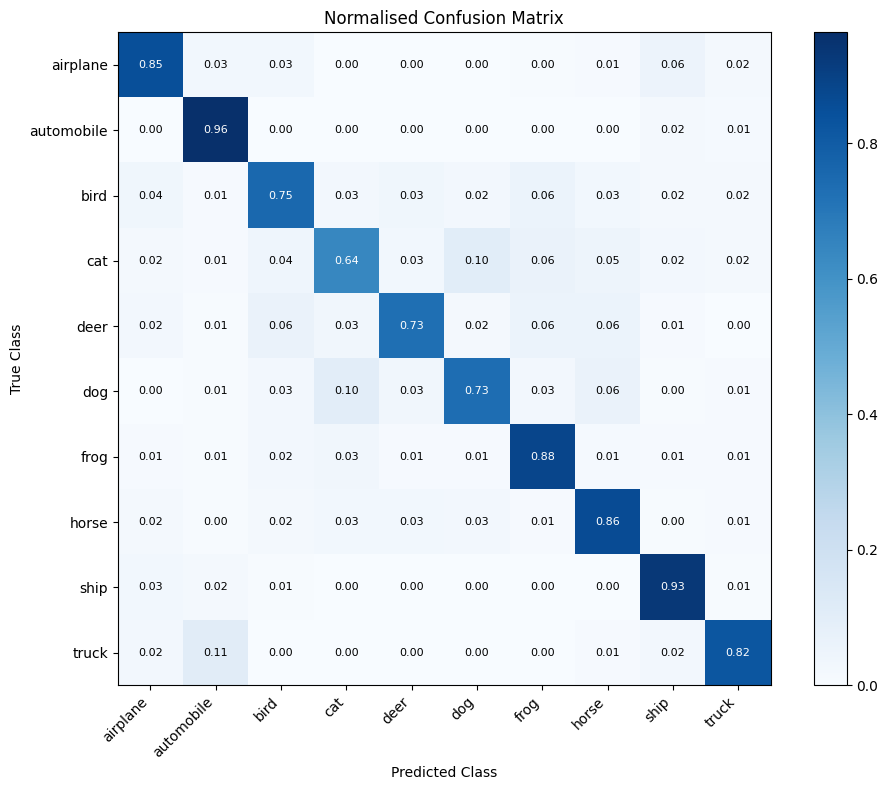

In [ ]:
cm_counts = confusion_matrix(y_test, y_pred)
cm_normalized = confusion_matrix(y_test, y_pred, normalize="true")

plt.figure(figsize=(10, 8))
img = plt.imshow(cm_normalized, interpolation="nearest", cmap="Blues")
plt.colorbar(img)
plt.xticks(np.arange(10), class_names, rotation=45, ha="right")
plt.yticks(np.arange(10), class_names)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Normalised Confusion Matrix")

threshold = cm_normalized.max() / 2
for i in range(10):
    for j in range(10):
        plt.text(
            j, i, f"{cm_normalized[i, j]:.2f}",
            ha="center", va="center",
            color="white" if cm_normalized[i, j] > threshold else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

In [ ]:
pair_scores = []
for i in range(10):
    for j in range(i + 1, 10):
        pair_scores.append((
            cm_counts[i, j] + cm_counts[j, i],
            cm_normalized[i, j] + cm_normalized[j, i],
            i, j
        ))

pair_scores.sort(reverse=True)
mutual_count, mutual_rate, class_a, class_b = pair_scores[0]

print("Top mutually confused pair:")
print(f"{class_names[class_a]} ↔ {class_names[class_b]}")
print("Two-way error count:", mutual_count)
print(f"Combined normalised confusion rate: {mutual_rate:.4f}")

Top mutually confused pair:
cat ↔ dog
Two-way error count: 183
Combined normalised confusion rate: 0.2033


### Analysis of the Highest Mutual Confusion

The highest mutual confusion occurred between the cat and dog classes, with 183 two-way classification errors and a combined normalised confusion rate of 0.2033. This indicates that approximately 20.33% of the combined cat-to-dog and dog-to-cat predictions were confused across both directions.

This confusion is understandable because cats and dogs share several visual characteristics, including fur texture, four-legged body structure, facial features, and similar poses. In addition, CIFAR-10 images have a low spatial resolution of 32 × 32 pixels, which limits the visibility of fine-grained discriminative details such as ear shape, muzzle structure, and facial proportions. Variations in background, lighting, object scale, and partial occlusion may further reduce the model's ability to distinguish between these two classes.

In [ ]:
train_acc = np.array(history.history["accuracy"])
val_acc = np.array(history.history["val_accuracy"])
train_loss = np.array(history.history["loss"])
val_loss = np.array(history.history["val_loss"])

best_val_epoch = int(np.argmax(val_acc)) + 1
min_loss_epoch = int(np.argmin(val_loss)) + 1
final_gap = float(train_acc[-1] - val_acc[-1])

print("Epochs:", len(train_loss))
print("Best validation accuracy epoch:", best_val_epoch)
print("Minimum validation loss epoch:", min_loss_epoch)
print(f"Final train-validation accuracy gap: {final_gap:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

if final_gap > 0.08 and val_loss[-1] > val_loss.min() * 1.10:
    diagnosis = "Overfitting"
elif train_acc[-1] < 0.65 and val_acc[-1] < 0.65:
    diagnosis = "Underfitting"
else:
    diagnosis = "Good generalisation with at most mild overfitting"

print("Diagnosis:", diagnosis)

Epochs: 41
Best validation accuracy epoch: 34
Minimum validation loss epoch: 34
Final train-validation accuracy gap: 0.0239
Test accuracy: 0.8168
Diagnosis: Good generalisation with at most mild overfitting


### Convergence Behaviour and Generalisation Diagnosis

The model demonstrated good generalisation with only mild overfitting. During approximately epochs 1–16, both training and validation accuracy increased substantially while their corresponding losses generally decreased, indicating effective feature learning. Between epochs 16 and 34, performance continued to improve more gradually as the network approached convergence.

The lowest validation loss and highest validation accuracy were both achieved at epoch 34. After this point, training accuracy continued to increase slightly, while validation performance plateaued and failed to produce further meaningful improvement. Consequently, Early Stopping terminated training at epoch 41 and restored the weights from epoch 34.

The final training accuracy was 84.20%, whereas validation accuracy was 81.81%, producing a relatively small gap of 2.39 percentage points. The unseen test accuracy was 81.68%, which was only approximately 0.13 percentage points below the final validation accuracy. Furthermore, the test loss of 0.5532 was very close to the minimum validation loss of 0.5550. These small metric differences indicate that the model did not severely memorise the training data and maintained stable performance on unseen samples. Therefore, the model exhibits good or near-optimal generalisation with only mild late-stage overfitting rather than underfitting or severe overfitting.

## 6. Model Interpretability and Error Analysis

In [ ]:
correct_indices = np.where(y_pred == y_test)[0]
incorrect_indices = np.where(y_pred != y_test)[0]

if len(correct_indices) < 3 or len(incorrect_indices) < 3:
    raise RuntimeError("Insufficient correct or incorrect samples.")

selected_correct = correct_indices[:3]
selected_incorrect = incorrect_indices[:3]
selected_indices = np.concatenate([selected_correct, selected_incorrect])

print("Correct indices:", selected_correct)
print("Incorrect indices:", selected_incorrect)

Correct indices: [1 2 3]
Incorrect indices: [0 4 9]


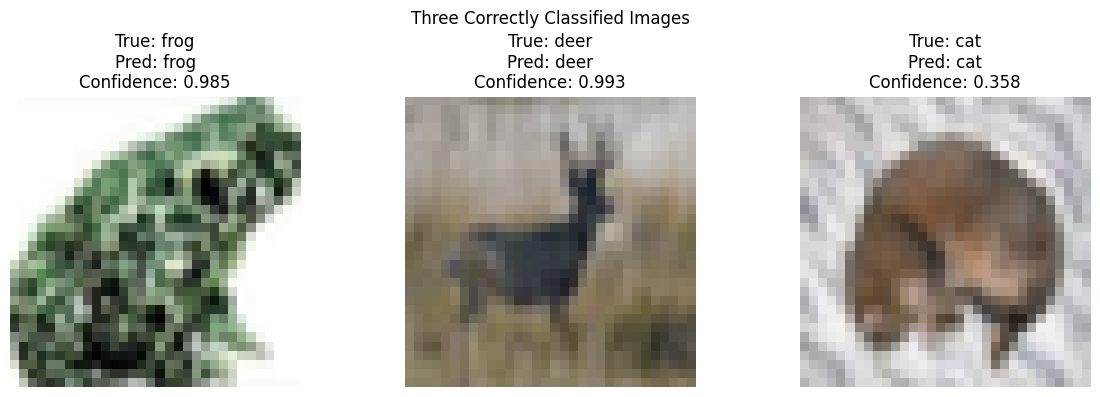

In [ ]:
plt.figure(figsize=(12, 4))
for pos, idx in enumerate(selected_correct):
    plt.subplot(1, 3, pos + 1)
    plt.imshow(x_test[idx])
    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}\n"
        f"Confidence: {y_prob[idx, y_pred[idx]]:.3f}"
    )
    plt.axis("off")
plt.suptitle("Three Correctly Classified Images")
plt.tight_layout()
plt.show()

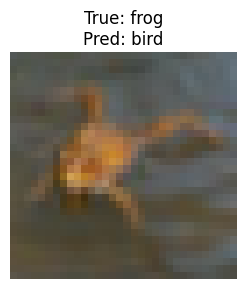

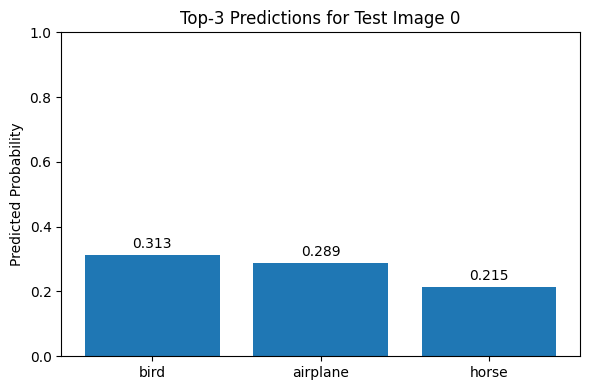

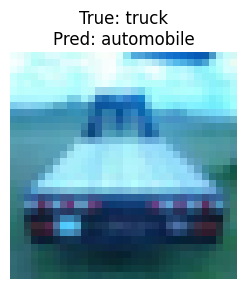

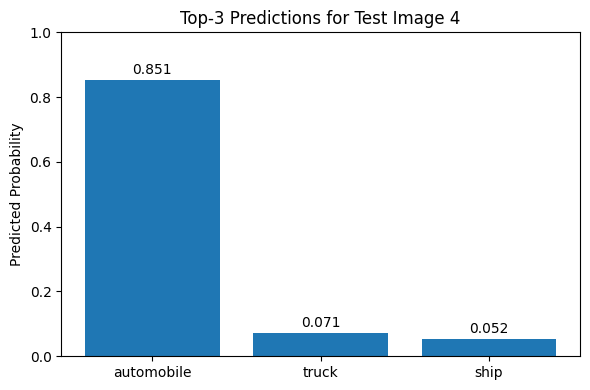

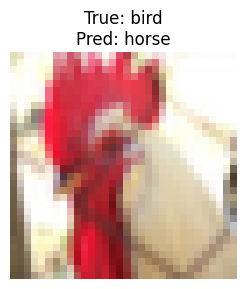

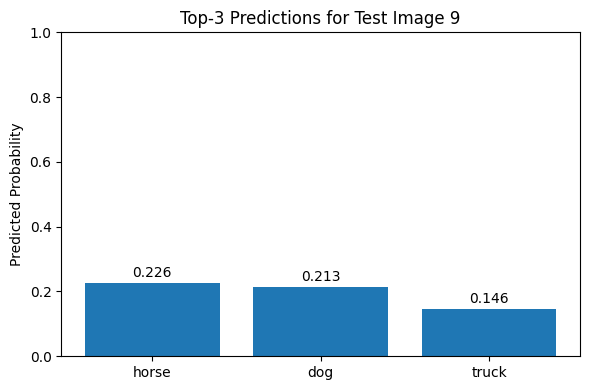

In [ ]:
for idx in selected_incorrect:
    top3 = np.argsort(y_prob[idx])[-3:][::-1]

    plt.figure(figsize=(4, 3))
    plt.imshow(x_test[idx])
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.bar([class_names[c] for c in top3], y_prob[idx, top3])
    plt.ylim(0, 1)
    plt.ylabel("Predicted Probability")
    plt.title(f"Top-3 Predictions for Test Image {idx}")
    for p, c in enumerate(top3):
        plt.text(p, y_prob[idx, c] + 0.02, f"{y_prob[idx, c]:.3f}", ha="center")
    plt.tight_layout()
    plt.show()

### Grad-CAM Interpretability and Error Analysis

The Grad-CAM visualisations show that the model generally learned meaningful spatial features, although its localisation quality varied across samples.

For the correctly classified frog image, the strongest activation was concentrated around the central body region of the frog. This indicates that the model used foreground texture and body shape rather than relying entirely on the plain background. Similarly, the correctly classified deer image produced a focused activation over the animal's torso, suggesting successful localisation of a semantic foreground feature. These examples demonstrate that the CNN can identify relevant object regions when the subject has a distinguishable silhouette.

For the correctly classified cat, however, the strongest activation appeared near the lower portion of the image and covered only part of the animal. This indicates that the model may have relied on a limited body region, surrounding contrast, or nearby background texture rather than representing the entire cat. Although the prediction was correct, the localisation suggests that the decision may be less robust than those for the frog and deer.

The misclassified frog was predicted as a bird. Its Grad-CAM map focused strongly on an upper region of the object and surrounding area rather than consistently covering the frog's complete body. The frog's extended limbs and low-resolution outline may have resembled the wings or body configuration of a bird. Background texture and motion-like blur may also have influenced this decision.

The truck image was misclassified as an automobile. Grad-CAM correctly activated over the central rear portion of the vehicle, meaning that the network recognised a relevant semantic object rather than the background. However, the heatmap did not reveal sufficient attention to truck-specific cues such as body size, cargo structure, or wheel arrangement. This error is therefore more likely caused by strong visual similarity between the two vehicle classes and limited CIFAR-10 resolution than by background noise.

The bird image was misclassified as a horse. The activation was concentrated around the bird's head and upper body. The close-up composition, partial visibility of the bird, and absence of a complete bird silhouette may have made its elongated head and neck region resemble features learned for horses. This represents a failure caused by ambiguous local features and occlusion rather than complete background dependence.

Overall, the Grad-CAM results indicate that the network usually learned localised semantic features, particularly for clearly visible foreground objects. Nevertheless, some predictions relied on partial object regions or visually ambiguous shapes. The errors appear to result mainly from low image resolution, class similarity, partial occlusion, and occasional attention to background or non-discriminative regions. The evidence does not establish strong dataset bias by itself, although background correlations may contribute to certain predictions.

In [ ]:
LAST_CONV_LAYER = "block4_conv2"

def make_gradcam_heatmap(image, trained_model, layer_name, predicted_class=None):
    image_batch = np.expand_dims(image, axis=0).astype("float32")

    grad_model = keras.Model(
        trained_model.inputs,
        [trained_model.get_layer(layer_name).output, trained_model.output]
    )

    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(image_batch, training=False)
        if predicted_class is None:
            predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(class_score, conv_output)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))
    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(conv_output * pooled_gradients, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    maximum = tf.reduce_max(heatmap)
    heatmap = tf.where(maximum > 0, heatmap / maximum, heatmap)
    return heatmap.numpy()

def overlay_gradcam(image, heatmap, alpha=0.40):
    resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (image.shape[0], image.shape[1])
    ).numpy().squeeze()

    coloured = plt.cm.jet(resized)[..., :3]
    return np.clip((1 - alpha) * image + alpha * coloured, 0, 1)

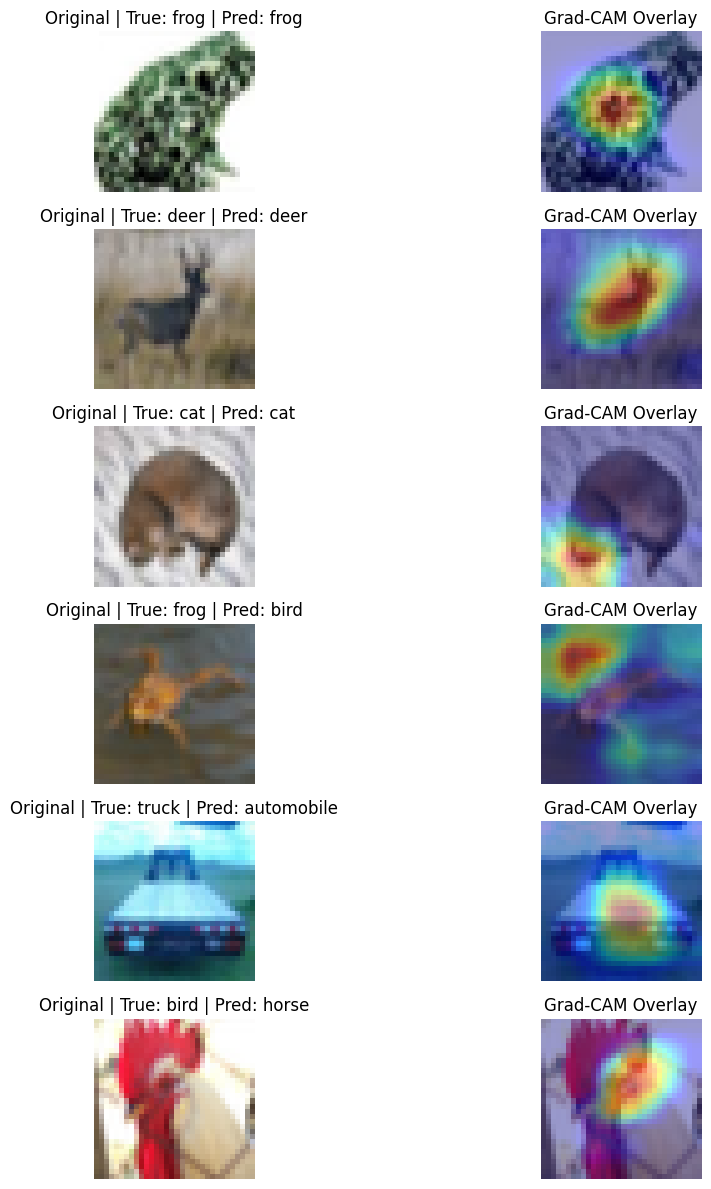

In [ ]:
plt.figure(figsize=(12, 12))

for row, idx in enumerate(selected_indices):
    predicted_class = int(y_pred[idx])
    heatmap = make_gradcam_heatmap(
        x_test[idx], model, LAST_CONV_LAYER,
        predicted_class=predicted_class
    )
    overlay = overlay_gradcam(x_test[idx], heatmap)

    plt.subplot(6, 2, row * 2 + 1)
    plt.imshow(x_test[idx])
    plt.title(
        f"Original | True: {class_names[y_test[idx]]} | "
        f"Pred: {class_names[predicted_class]}"
    )
    plt.axis("off")

    plt.subplot(6, 2, row * 2 + 2)
    plt.imshow(overlay)
    plt.title("Grad-CAM Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Grad-CAM Interpretability Analysis

The Grad-CAM visualisations indicate that the CNN generally learned meaningful semantic features rather than relying solely on background information.

For the correctly classified frog image, the strongest activation was concentrated around the frog's body, indicating that the network successfully focused on the main foreground object. Similarly, the deer image showed a broad activation covering most of the animal, demonstrating effective localisation of important semantic features. These examples suggest that the model learned object-specific representations that contributed to correct predictions.

The correctly classified cat image showed a comparatively smaller activation region near the lower portion of the object. Although the prediction was correct, the model assigned a relatively lower confidence score (35.8%), indicating that the extracted features were less distinctive than those observed for the frog and deer. This suggests that the model experienced greater uncertainty when distinguishing visually similar animal categories.

For the misclassified frog image, the network predicted the class as bird. The activation focused on only part of the object rather than the complete frog, suggesting that local shape information may have resembled bird-like features. The truck image, which was predicted as an automobile, activated primarily over the vehicle itself, indicating that the error resulted from strong visual similarity between the two vehicle categories rather than background interference. Likewise, the bird image predicted as a horse demonstrated that low image resolution and incomplete object features can cause the network to emphasise ambiguous local patterns instead of fully discriminative semantic characteristics.

Overall, the Grad-CAM results demonstrate that the CNN generally learned meaningful object-centred features. Most classification errors appear to be caused by low image resolution, visual similarity between classes, and partial object visibility rather than severe background bias.